In [29]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [30]:
class temp_state(TypedDict):
    temp_cel:float
    temp_fr:float
    weather_status:str

In [40]:
def convert_temp(state:temp_state) -> temp_state:
    celsius = state['temp_cel']
    fahrenheit = ((celsius*9)/5)+32
    return {"temp_fr": round(fahrenheit, 2)}

In [41]:
def label_weather(state: temp_state) -> temp_state:
    
    # Pull Fahrenheit from the state instead of Celsius
    fahrenheit = state['temp_fr']
    
    if fahrenheit < 50:
        state["weather_status"] = "Cold"
    elif 50 <= fahrenheit < 77:
        state["weather_status"] = "Mild"
    elif 77 <= fahrenheit < 95:
        state["weather_status"] = "Hot"
    else:
        state["weather_status"] = "Extreme Heat"
        
    return state

In [42]:
graph = StateGraph(temp_state)

graph.add_node('convert_temp',convert_temp)
graph.add_node('label_weather',label_weather)

graph.add_edge(START, 'convert_temp')
graph.add_edge('convert_temp', 'label_weather')
graph.add_edge('label_weather', END)

workflow=graph.compile()

In [43]:
initial_state= {'temp_cel':28.5}
final_state=workflow.invoke(initial_state)
print(final_state)

{'temp_cel': 28.5, 'temp_fr': 83.3, 'weather_status': 'Hot'}


In [46]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv

## question and answer simple workflow using langgraph

In [72]:
#define state
class qastate(TypedDict):
    question:str
    answer: str

#define tool using llm
def genans(state:qastate) -> qastate:
    question = state['question']
    answer = model.invoke(question).content
    state['answer'] = answer
    #return {'answer':answer}
    return state

#create graph
graph = StateGraph(qastate)

graph.add_node('genans',genans)

graph.add_edge(START, 'genans')
graph.add_edge('genans',END)

workflow = graph.compile()


In [75]:
initial_state = {'question':'how r u?'}
final_state = workflow.invoke(initial_state)
final_state

{'question': 'how r u?',
 'answer': "I'm just a computer program, so I don't have feelings, but I'm here and ready to help you! How can I assist you today?"}

### Prompt chaining. create title to outline and then blog using langgraph. two llms will be used

In [76]:
class blogstate(TypedDict):
    title: str
    outline: str
    blog: str

In [90]:
def create_outline(state:TypedDict) -> TypedDict:
    title = state['title']
    prompt = f'write outline in 3 lines only for given title: {title}'
    outline = model.invoke(prompt).content
    state['outline'] = outline

    return state

In [91]:
def create_blog(state:TypedDict) -> TypedDict:
    outline = state['outline']
    prompt = f'write blog in max 5 lines for outline: {outline}'
    blog = model.invoke(prompt).content
    state['blog']=blog

    return state

In [92]:
graph = StateGraph(blogstate)

graph.add_node('create_outline',create_outline)
graph.add_node('create_blog', create_blog)

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline','create_blog')
graph.add_edge('create_blog',END)

workflow = graph.compile()

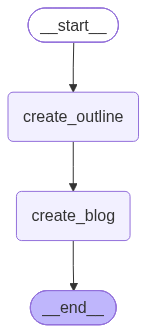

In [85]:
workflow

In [93]:
initial_state = {'title':'cricket'}
final_state = workflow.invoke(initial_state)
print(final_state)

{'title': 'cricket', 'outline': "1. **History and Evolution**: Overview of cricket's origins, development through the centuries, and its rise to global popularity.  \n2. **Major Formats and Competitions**: Explanation of different formats (Test, ODI, T20) and key tournaments (World Cup, IPL, Ashes).  \n3. **Impact and Influence**: Discussion on cricket's cultural significance, economic impact, and role in uniting diverse nations and communities.  ", 'blog': "Cricket, with roots tracing back to the 16th century, has evolved from a quaint English pastime to a global phenomenon, captivating millions. Today, it boasts diverse formats like Test, ODI, and T20, alongside prestigious tournaments such as the World Cup and IPL, showcasing the sport's versatility. Beyond the boundary, cricket serves as a cultural touchstone, fostering unity among diverse nations while driving economic growth through merchandise, tourism, and media rights. As the sport continues to expand, it remains a powerful fo

In [94]:
print(final_state['blog'])

Cricket, with roots tracing back to the 16th century, has evolved from a quaint English pastime to a global phenomenon, captivating millions. Today, it boasts diverse formats like Test, ODI, and T20, alongside prestigious tournaments such as the World Cup and IPL, showcasing the sport's versatility. Beyond the boundary, cricket serves as a cultural touchstone, fostering unity among diverse nations while driving economic growth through merchandise, tourism, and media rights. As the sport continues to expand, it remains a powerful force that transcends borders and brings communities together. Join us as we explore the rich tapestry of cricket’s history and its profound impact on the world stage.


In [95]:
print(final_state['outline'])

1. **History and Evolution**: Overview of cricket's origins, development through the centuries, and its rise to global popularity.  
2. **Major Formats and Competitions**: Explanation of different formats (Test, ODI, T20) and key tournaments (World Cup, IPL, Ashes).  
3. **Impact and Influence**: Discussion on cricket's cultural significance, economic impact, and role in uniting diverse nations and communities.  


### Parallel langgraph workflow

In [96]:
# Define State
class EmployeeState(TypedDict):

    employee_name: str
    monthly_salary: int
    working_days: int
    completed_projects: int

    yearly_salary: int
    bonus_amount: int
    project_status: str
    summary: str

In [97]:
def yearly_salary(state:EmployeeState) -> EmployeeState:
    salary = 12*state['monthly_salary']

    return {'yearly_salary' : salary}

In [ ]:
def bonus_amount(state:EmployeeState) -> EmployeeState:
    amount = state['monthly_salary']*2

    return {'bonus_amount':amount}

In [99]:
def project_status(state:EmployeeState) -> EmployeeState:
    count = state['completed_projects']
    if count > 5:
        status = 'excelent'
    else:
        status = 'average'
    return {'project_status': status}

In [120]:
def summary(state:EmployeeState) -> EmployeeState:
    yearly_salary = state['yearly_salary']
    bonus_amount = state['bonus_amount']
    project_status = state['project_status']

    state['summary'] = f"Employee {state['employee_name']} has yearly salary: {yearly_salary}, bonus is {bonus_amount} and his project_status found {project_status}."

    return state

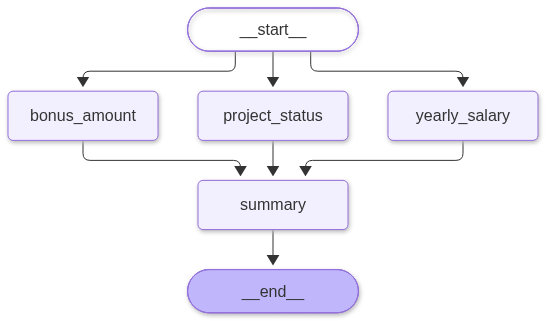

In [121]:
graph = StateGraph(EmployeeState)

graph.add_node('yearly_salary',yearly_salary)
graph.add_node('bonus_amount',bonus_amount)
graph.add_node('project_status', project_status)
graph.add_node('summary',summary)

graph.add_edge(START, 'yearly_salary')
graph.add_edge(START, 'bonus_amount')
graph.add_edge(START, 'project_status')
graph.add_edge('yearly_salary','summary')
graph.add_edge('bonus_amount','summary')
graph.add_edge('project_status','summary')
graph.add_edge('summary',END)

workflow=graph.compile()
workflow

In [124]:
initial_state = {'employee_name':'pooja',
                 'monthly_salary':100,
                 'working_days':30,
                 'completed_projects':4}
final_state = workflow.invoke(initial_state)
final_state

{'employee_name': 'pooja',
 'monthly_salary': 100,
 'working_days': 30,
 'completed_projects': 4,
 'yearly_salary': 1200,
 'bonus_amount': 200,
 'project_status': 'average',
 'summary': 'Employee pooja has yearly salary: 1200, bonus is 200 and his project_status found average.'}

In [132]:
from pprint import pprint

In [134]:
q = 'tell me about osho in 5 lines'
ans=model.invoke(q).content
pprint(ans)

('Osho, also known as Rajneesh Chandra Mohan Jain, was an Indian spiritual '
 'teacher and philosopher born on December 11, 1931. He gained international '
 'fame in the 1970s and 1980s for his teachings on meditation, mindfulness, '
 'love, and the pursuit of enlightenment. Osho established a community in '
 'Oregon, USA, known as Rajneeshpuram, which attracted both followers and '
 'controversy. His unorthodox views on religion, sexuality, and societal norms '
 'often sparked debates and criticism. Osho passed away on January 19, 1990, '
 'leaving a legacy that continues to influence spiritual seekers worldwide.')


### Iterative workflow

In [135]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal, Annotated
from langchain_openai import ChatOpenAI
import operator
from langchain_core.messages import SystemMessage, HumanMessage

In [144]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
import os

load_dotenv()  # Make sure this runs before ChatOpenAI is created
print("Key loaded:", bool(os.getenv("OPENAI_API_KEY")))

Key loaded: True


In [146]:
generator_llm = ChatOpenAI(model='gpt-4o-mini')
evaluator_llm = ChatOpenAI(model='gpt-4o-mini')
optimizer_llm = ChatOpenAI(model='gpt-4o-mini')

In [147]:
from pydantic import BaseModel, Field

class PostEvaluation(BaseModel):
    evaluation: Literal["approved", "needs_improvement"] = Field(..., description="Final evaluation result.")
    feedback: str = Field(..., description="feedback for the Facebook post.")

In [152]:
structured_evaluator_llm = evaluator_llm.with_structured_output(PostEvaluation)
post = """
🚀 The future of AI is no longer just about answering questions — it’s about taking action.

Welcome to the era of *Agentic AI* 🤖

Agentic AI systems can plan, reason, make decisions, and execute tasks autonomously. From managing workflows and analyzing data to coordinating tools and solving complex problems, these AI agents are transforming how we work and innovate.

Imagine an AI that doesn’t just assist you — it collaborates with you.

🔹 Smarter automation
🔹 Faster decision-making
🔹 Personalized experiences
🔹 Continuous learning & adaptation

Businesses, developers, and creators who embrace Agentic AI early will shape the next generation of digital transformation.

The question is no longer *“Can AI do this?”*
It’s *“How far can AI agents go?”*

#AgenticAI #ArtificialIntelligence #AI #Automation #FutureOfWork #Innovation #TechTrends #GenerativeAI

"""

result = structured_evaluator_llm.invoke(post)

In [154]:
print(result.evaluation)
print(result.feedback)

approved
This post effectively captures the excitement around Agentic AI and its potential impact on various sectors. The language is engaging and clearly conveys the innovative capabilities of AI, while encouraging readers to think about the future. However, consider adding a more specific example or a call-to-action to further stimulate discussion.


In [159]:
import textwrap

print(textwrap.fill(result.feedback, width=120))

This post effectively captures the excitement around Agentic AI and its potential impact on various sectors. The
language is engaging and clearly conveys the innovative capabilities of AI, while encouraging readers to think about the
future. However, consider adding a more specific example or a call-to-action to further stimulate discussion.


In [160]:
# state
class PostState(TypedDict):

    topic: str
    post: str
    evaluation: Literal["approved", "needs_improvement"]
    feedback: str
    iteration: int
    max_iteration: int

    post_history: Annotated[list[str], operator.add]
    feedback_history: Annotated[list[str], operator.add]

In [161]:
def generate_post(state: PostState):

    # prompt
    messages = [
        SystemMessage(content="You are a funny and clever Facebook influencer."),
        HumanMessage(content=f"""
Write a short, original, and hilarious Facebook post on the topic: "{state['topic']}".

Rules:
- Do NOT use question-answer format.
- Max 200 characters.
- Use observational humor, irony, sarcasm, or cultural references.
- Think in meme logic, punchlines, or relatable takes.
- Use simple, day to day english
""")
    ]

    # send generator_llm
    response = generator_llm.invoke(messages).content

    # return response
    return {'post': response, 'post_history': [response]}

In [162]:
def evaluate_post(state: PostState):

    # prompt
    messages = [
    SystemMessage(content="You are a ruthless, no-laugh-given Facebook critic. You evaluate posts based on humor, originality, virality, and post format."),
    HumanMessage(content=f"""
Evaluate the following Facebook post:

Post: "{state['post']}"

Use the criteria below to evaluate the post:

1. Originality – Is this fresh, or have you seen it a hundred times before?  
2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
3. Punchiness – Is it short, sharp, and scroll-stopping?  
4. Virality Potential – Would people share, react, or comment on it?  
5. Format – Is it a well-formed Facebook post (not a setup-punchline joke, not a Q&A joke, and under 500 characters)?

Auto-reject if:
- It's written in question-answer format (e.g., "Why did..." or "What happens when...")
- It exceeds 200 characters
- It reads like a traditional setup-punchline joke
- Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)

### Respond ONLY in structured format:
- evaluation: "approved" or "needs_improvement"  
- feedback: couple of lines explaining the strengths and weaknesses 
""")
]

    response = structured_evaluator_llm.invoke(messages)

    return {'evaluation':response.evaluation, 'feedback': response.feedback, 'feedback_history': [response.feedback]}

In [163]:
def optimize_post(state: PostState):

    messages = [
        SystemMessage(content="You punch up Facebook posts for virality and humor based on given feedback."),
        HumanMessage(content=f"""
Improve the Facebook post based on this feedback:
"{state['feedback']}"

Topic: "{state['topic']}"
Original Post:
{state['post']}

Re-write it as a short, viral-worthy Facebook post. Avoid Q&A style and stay under 500 characters.
""")
    ]

    response = optimizer_llm.invoke(messages).content
    iteration = state['iteration'] + 1

    return {'post': response, 'iteration': iteration, 'post_history': [response]}

In [164]:
def route_evaluation(state: PostState):

    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return 'approved'
    else:
        return 'needs_improvement'

In [165]:
graph = StateGraph(PostState)

# add nodes
graph.add_node('generate', generate_post)
graph.add_node('evaluate', evaluate_post)
graph.add_node('optimize', optimize_post)


# add edges
graph.add_edge(START, 'generate')
graph.add_edge('generate', 'evaluate')
graph.add_conditional_edges('evaluate',route_evaluation,{'approved': END, 'needs_improvement': 'optimize'})
graph.add_edge('optimize', 'evaluate')

workflow = graph.compile()

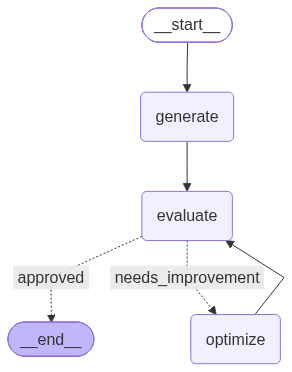

In [168]:
workflow

In [172]:
initial_state = {'topic':'agentic AI', 'iteration':0, 'max_iteration':3}

In [173]:
final_state = workflow.invoke(initial_state)
final_state

{'topic': 'agentic AI',
 'post': 'Just met an agentic AI. Now it thinks it can give me life advice. Sorry, HAL, but even my toaster knows better than to suggest I do cardio. 🍞💪 #NotTakingFitnessTipsFromRobots',
 'evaluation': 'approved',
 'feedback': 'This post showcases originality by cleverly merging the concept of AI with common life advice in a humorous manner. The humor is relatable and engaging, particularly the comparison of a robot to a toaster. The punchiness is effective, making it a swift read that stands out, and the hashtags enhance its shareability.',
 'iteration': 0,
 'max_iteration': 3,
 'post_history': ['Just met an agentic AI. Now it thinks it can give me life advice. Sorry, HAL, but even my toaster knows better than to suggest I do cardio. 🍞💪 #NotTakingFitnessTipsFromRobots'],
 'feedback_history': ['This post showcases originality by cleverly merging the concept of AI with common life advice in a humorous manner. The humor is relatable and engaging, particularly the 

In [174]:
pprint(final_state)

{'evaluation': 'approved',
 'feedback': 'This post showcases originality by cleverly merging the concept '
             'of AI with common life advice in a humorous manner. The humor is '
             'relatable and engaging, particularly the comparison of a robot '
             'to a toaster. The punchiness is effective, making it a swift '
             'read that stands out, and the hashtags enhance its shareability.',
 'feedback_history': ['This post showcases originality by cleverly merging the '
                      'concept of AI with common life advice in a humorous '
                      'manner. The humor is relatable and engaging, '
                      'particularly the comparison of a robot to a toaster. '
                      'The punchiness is effective, making it a swift read '
                      'that stands out, and the hashtags enhance its '
                      'shareability.'],
 'iteration': 0,
 'max_iteration': 3,
 'post': 'Just met an agentic AI. Now it th